# Early dropout sur Fashion-MNIST (MLP et CNN)

Papier : *Dropout Reduces Underfitting* (Liu et al., ICML 2023). L'idée : mettre du dropout seulement au **début** de l'entraînement puis le couper (early dropout) aiderait les modèles qui **sous-apprennent**. Le papier le montre sur ImageNet avec des modèles de 5 à 20 M de paramètres, et reste flou sur ce que "début" veut dire.

Nous on teste ça sur des modèles du cours, 100 à 1000 fois plus petits, avec deux questions :
- **Q1** : est-ce que l'early dropout marche à notre échelle, et sur quels modèles ?
- **Q2** : quelle durée de dropout est la bonne ? Est-ce vraiment sans importance comme le dit le papier (de 1 % à 50 % de l'entraînement) ?

La démarche, dans l'ordre du notebook :
1. **Calibration** : trouver pour chaque modèle un réglage (largeur, nb d'epochs) où il sous-apprend, sinon le papier ne prédit rien.
2. **Grille principale** : dans ce réglage, tester plusieurs durées d'early dropout sur 5 seeds.
3. **Budget plus court** : voir si le résultat dépend du nombre d'epochs.
4. **Contrôle** : vérifier que dans un réglage qui surapprend on trouve bien l'inverse.
5. **Sensibilité au taux** : refaire à p = 0.3 (le taux utilisé par le groupe CIFAR-10).

Chaque run est sauvegardé en CSV dans `resultats/`. Les runs déjà faits sont sautés, donc relancer tout le notebook prend quelques secondes : il relit juste les CSV.

In [ ]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
from torch import nn
from torchvision import datasets

# from google.colab import drive
# drive.mount("/content/drive")
# os.chdir("/content/drive/MyDrive/early-dropout")


from config import BATCH, P, EARLY_GRID      # 128, 0.1, [0, 0.05, 0.1, 0.2, 0.3, 0.5, 1]
from models import mlp, cnn
from train import entrainer

device = "cuda" if torch.cuda.is_available() else "cpu"
print(device)

cpu


## Le protocole (fixé avant de regarder les résultats)

Tout est identique d'un run à l'autre, sauf ce qu'on étudie (la durée du dropout) :

| Choix | Valeur | Pourquoi |
|---|---|---|
| Optimiseur | Adam, lr 1e-3, pas de weight decay | le plus standard, et pas d'autre régularisation qui se mélange au dropout |
| Schedule | cosinus jusqu'à 0, sans warmup | le lr suit le même chemin quel que soit le dropout (pas le cas avec ReduceLROnPlateau) |
| Batch | 128 | |
| Augmentation | aucune | sinon le sous-apprentissage viendrait de l'augmentation et pas du modèle |
| Dropout | p = 0.1, après chaque couche cachée (MLP) ou chaque bloc (CNN) | taux de base du papier pour les petits modèles |
| Early dropout | p constant pendant `frac` × epochs, puis 0 | le plus simple à décrire ; le papier montre que constant ou linéaire donnent pareil (Tab. 3b) |
| Validation | 10 000 images tirées du train (seed 0) | tous les choix se font dessus, le test sert juste au chiffre final |
| Seeds | 5 (2 pour la calibration, 3 pour le contrôle) | une même seed = mêmes poids de départ, donc on compare seed par seed |
| Valeur d'un run | moyenne des 5 dernières epochs | lisse le bruit d'une epoch à l'autre |

`frac` = durée du dropout en fraction du nombre d'epochs : 0 = sans dropout, 1 = dropout classique (tout le long), entre les deux = early dropout.

Les mesures (loss et accuracy) sont toujours faites sans dropout, en mode eval. La loss d'entraînement est mesurée sur 10 000 images fixes du train.

In [68]:
tr = datasets.FashionMNIST("./data", train=True, download=True)
te = datasets.FashionMNIST("./data", train=False, download=True)
Xtr, Xte = tr.data.float().unsqueeze(1) / 255, te.data.float().unsqueeze(1) / 255     # (N, 1, 28, 28)
ytr, yte = tr.targets, te.targets

# validation : 10 000 images du train, toujours les mêmes
perm = torch.randperm(len(Xtr), generator=torch.Generator().manual_seed(0))
Xva, yva = Xtr[perm[:10000]], ytr[perm[:10000]]
Xtr, ytr = Xtr[perm[10000:]], ytr[perm[10000:]]

# normalisation avec les stats du train uniquement
mu, sd = Xtr.mean(), Xtr.std()
Xtr, Xva, Xte = (Xtr - mu) / sd, (Xva - mu) / sd, (Xte - mu) / sd

images = {k: v.to(device) for k, v in dict(Xtr=Xtr, ytr=ytr, Xva=Xva, yva=yva, Xte=Xte, yte=yte).items()}   # pour le CNN
vecteurs = {k: (v.flatten(1) if k.startswith("X") else v) for k, v in images.items()}                        # pour le MLP (784)
print(Xtr.shape, Xva.shape, Xte.shape)

torch.Size([50000, 1, 28, 28]) torch.Size([10000, 1, 28, 28]) torch.Size([10000, 1, 28, 28])


## Les 3 petites fonctions du notebook

Pour ne pas recopier la même boucle partout :
- `lancer` : fait **un run** et l'écrit dans un CSV (ou ne fait rien si le CSV existe déjà). L'entraînement lui-même est dans `train.py` (`entrainer`).
- `tableau_calibration` : pour chaque (largeur, epochs), compare sans dropout et dropout classique.
- `gains` : pour chaque durée, la différence avec le run sans dropout, seed par seed, avec un intervalle de confiance.

In [69]:
# un "cadre" = un modèle + ses données. L est la largeur (neurones par couche pour le MLP, canaux du 1er bloc pour le CNN)
CADRES = {
    "mlp_fmnist": (lambda L: mlp(784, 10, couche_cache=L), vecteurs),
    "cnn_fmnist": (lambda L: cnn(1, 10, largeur=L), images),
}

def fichier(cadre, L, E, frac, seed, dossier="resultats"):
    return f"{dossier}/{cadre}_w{L}_e{E}_frac{frac}_s{seed}.csv"

def lancer(cadre, L, E, frac, seed, p=P, dossier="resultats"):
    f = fichier(cadre, L, E, frac, seed, dossier)
    if os.path.exists(f):
        return                                   # déjà fait
    creer, data = CADRES[cadre]
    torch.manual_seed(seed)                      # même seed = mêmes poids de départ
    model, opt = creer(L)
    model.to(device)
    hist = entrainer(model, opt, data, E, t_early=round(frac * E), p=p, batch=BATCH)
    hist.assign(cadre=cadre, width=L, epochs=E, frac=frac, seed=seed).to_csv(f, index=False)
    print(f, " val acc", round(hist.val_acc.tail(5).mean(), 4))

In [70]:
def tableau_calibration(cadre, largeurs, budgets, seeds=[0, 1]):
    lignes = []
    for L in largeurs:
        for E in budgets:
            sans = [pd.read_csv(fichier(cadre, L, E, 0, s)) for s in seeds]      # sans dropout
            avec = [pd.read_csv(fichier(cadre, L, E, 1, s)) for s in seeds]      # dropout classique
            # delta = acc val (dropout classique) - acc val (sans dropout), en points, pour chaque seed
            delta = [100 * (a.val_acc.tail(5).mean() - b.val_acc.tail(5).mean()) for a, b in zip(avec, sans)]
            lignes.append({
                "largeur": L, "epochs": E,
                "acc_sans_dropout": np.mean([d.val_acc.tail(5).mean() for d in sans]),
                "delta_moy": np.mean(delta),
                "delta_max": max(delta),          # la seed la moins négative
                # de combien la val loss remonte entre son minimum et la fin du run
                "remontee_val_loss": np.mean([d.val_loss.tail(5).mean() / d.val_loss.min() - 1 for d in sans]),
            })
    tab = pd.DataFrame(lignes).set_index(["largeur", "epochs"])
    tab["sous_apprentissage"] = tab.delta_max <= -0.5                          # toutes les seeds perdent au moins 0.5 pt
    tab["acc_ok"] = tab.acc_sans_dropout >= 0.9 * tab.acc_sans_dropout.max()   # le modèle apprend quand même
    tab["valide"] = tab.sous_apprentissage & tab.acc_ok & (tab.remontee_val_loss < 0.02)
    return tab.round(3)

In [71]:
T95 = {2: 12.71, 3: 4.30, 5: 2.78}       # quantile de Student à 95 % selon le nb de seeds
METRIQUES = ["train_loss", "val_loss", "val_acc", "test_acc"]

def fin_de_run(f):
    return pd.read_csv(f).tail(5)[METRIQUES].mean()        # moyenne des 5 dernières epochs

def gains(cadre, L, E, fracs, seeds, dossier="resultats", reference=None):
    # pour chaque durée : (run avec dropout) - (run sans dropout de la même seed), puis moyenne et IC sur les seeds
    reference = reference or cadre
    lignes = {}
    for frac in fracs:
        d = pd.DataFrame([fin_de_run(fichier(cadre, L, E, frac, s, dossier)) - fin_de_run(fichier(reference, L, E, 0, s))
                          for s in seeds])
        d[["val_acc", "test_acc"]] *= 100                  # accuracy en points
        ic = T95[len(seeds)] * d.std() / len(seeds) ** 0.5
        lignes[frac] = pd.concat([d.mean(), ic.add_prefix("ic_")])
    colonnes = [c for m in METRIQUES for c in (m, "ic_" + m)]
    return pd.DataFrame(lignes).T[colonnes].round(3)

**Comment lire un tableau de `gains`** : une ligne par durée de dropout. `train_loss`, `val_loss` = écart de loss avec le run sans dropout (négatif = mieux). `val_acc`, `test_acc` = écart d'accuracy en points (positif = mieux). Les colonnes `ic_` donnent la demi-largeur de l'intervalle de confiance à 95 % : **l'effet est significatif si le gain est plus grand que son `ic`** (en valeur absolue). Sinon on ne peut pas le distinguer du bruit entre seeds.

Avec 5 seeds on ne voit que les effets assez gros, et on regarde beaucoup de lignes sans corriger : un "significatif" isolé peut être un hasard, on se fie aux tendances qui se répètent.

---
## 1. Calibration : trouver un réglage où le modèle sous-apprend

Le papier ne prédit un gain que si le modèle sous-apprend. Il faut donc le vérifier et pas le supposer. On utilise le critère du papier comme thermomètre : on entraîne le même modèle sans dropout puis avec dropout classique, et on regarde

> delta = accuracy val (dropout classique) − accuracy val (sans dropout)

Le dropout classique enlève de la capacité au modèle. Si le modèle surapprend ça l'aide (delta > 0). S'il manque déjà de capacité ça le pénalise (delta < 0) : c'est le sous-apprentissage qu'on cherche.

Une case (largeur, epochs) est **valide** si :
1. toutes les seeds perdent au moins 0.5 pt (`delta_max ≤ -0.5`) ;
2. l'accuracy sans dropout fait au moins 90 % de la meilleure de la grille (sinon on étudie un modèle qui n'apprend rien) ;
3. la val loss sans dropout remonte de moins de 2 % à la fin (sinon il commence déjà à surapprendre).

Parmi les cases valides on prend **le budget le plus long**, puis la plus grande largeur. Le budget long, c'est pour que le modèle ait fini de converger : sinon un gain pourrait juste vouloir dire "ça va plus vite", pas "ça arrive à un meilleur point".

### MLP (2 couches cachées)

In [72]:
for L in [16, 32, 64]:
    for E in [10, 20, 50]:
        for frac in [0, 1]:
            for seed in [0, 1]:
                lancer("mlp_fmnist", L, E, frac, seed)

tableau_calibration("mlp_fmnist", [16, 32, 64], [10, 20, 50])

acc_sans_dropout  delta_moy  delta_max  remontee_val_loss  \
largeur epochs                                                              
16      10                 0.857     -1.024     -0.950              0.013   
        20                 0.865     -1.080     -0.994              0.002   
        50                 0.868     -1.110     -0.982              0.001   
32      10                 0.870     -0.358     -0.268              0.019   
        20                 0.879     -0.365     -0.308              0.003   
        50                 0.883     -0.370     -0.166              0.062   
64      10                 0.880     -0.129     -0.070              0.020   
        20                 0.888     -0.054      0.050              0.003   
        50                 0.886      0.447      0.528              0.299   

                sous_apprentissage  acc_ok  valide  
largeur epochs                                      
16      10                    True    True    True  
        20                    True    True    True  
        50                    True    True    True  
32      10                   False    True   False  
        20                   False    True   False  
        50                   False    True   False  
64      10                   False    True   False  
        20                   False    True   False  
        50                   False    True   False

C'est la largeur qui décide du régime : seul le MLP à 16 neurones perd nettement avec le dropout classique (≈ -1 pt), à tous les budgets. À 32 neurones la perte est trop petite (≈ -0.4 pt), et à 64 neurones sur 50 epochs le dropout se met à aider (+0.45 pt) pendant que la val loss remonte de 30 % : ce réglage surapprend, on s'en servira comme **contrôle**.

→ On retient **MLP largeur 16, 50 epochs** (13 000 paramètres).

### CNN (3 blocs conv-conv-maxpool)

In [73]:
for L in [4, 8, 16]:
    for E in [10, 20, 50]:
        for frac in [0, 1]:
            for seed in [0, 1]:
                lancer("cnn_fmnist", L, E, frac, seed)

tableau_calibration("cnn_fmnist", [4, 8, 16], [10, 20, 50])

acc_sans_dropout  delta_moy  delta_max  remontee_val_loss  \
largeur epochs                                                              
4       10                 0.804     -1.436     -0.842              0.023   
        20                 0.840     -0.645      0.070              0.006   
        50                 0.876     -1.780     -1.140              0.000   
8       10                 0.860     -0.966     -0.366              0.043   
        20                 0.891     -0.737     -0.514              0.011   
        50                 0.908      0.102      0.106              0.015   
16      10                 0.887     -0.003      0.272              0.047   
        20                 0.911      0.021      0.232              0.010   
        50                 0.915      0.904      1.166              0.652   

                sous_apprentissage  acc_ok  valide  
largeur epochs                                      
4       10                    True   False   False  
        20                   False    True   False  
        50                    True    True    True  
8       10                   False    True   False  
        20                    True    True    True  
        50                   False    True   False  
16      10                   False    True   False  
        20                   False    True   False  
        50                   False    True   False

Même logique que le MLP et que la Fig. 5 du papier : plus le modèle est petit, plus le dropout classique le pénalise ; plus il est gros et entraîné longtemps, plus il l'aide. Deux cases sont valides : largeur 4 à 50 epochs et largeur 8 à 20 epochs. La largeur 4 à 10 epochs sous-apprend aussi mais son accuracy est trop basse (critère 2).

→ D'après la règle (budget le plus long) on retient **CNN largeur 4, 50 epochs** (4 700 paramètres). La largeur 8 à 20 epochs servira de deuxième point à l'étape 3, et la largeur 16 à 50 epochs (delta +0.9 pt, val loss qui remonte de 65 %) de **contrôle**.

---
## 2. Grille principale : quelle durée de dropout ?

Dans les deux réglages retenus, on teste toutes les durées de `EARLY_GRID` sur 5 seeds. À 50 epochs ça fait 2, 5, 10, 15 et 25 epochs de dropout (le 0.05 donne 2 epochs car python arrondit 2.5 à 2).

In [74]:
SEEDS = [0, 1, 2, 3, 4]

for frac in EARLY_GRID:
    for seed in SEEDS:
        lancer("mlp_fmnist", 16, 50, frac, seed)
        lancer("cnn_fmnist", 4, 50, frac, seed)

g_mlp = gains("mlp_fmnist", 16, 50, EARLY_GRID[1:], SEEDS)
g_mlp

,train_loss,ic_train_loss,val_loss,ic_val_loss,val_acc,ic_val_acc,test_acc,ic_test_acc
0.05,-0.013,0.006,0.004,0.006,0.048,0.245,0.130,0.332
0.10,-0.011,0.002,0.008,0.006,-0.106,0.326,0.119,0.438
0.20,-0.006,0.004,0.009,0.005,-0.220,0.323,-0.062,0.386
0.30,-0.001,0.003,0.011,0.006,-0.378,0.383,-0.096,0.307
0.50,0.012,0.003,0.015,0.006,-0.670,0.415,-0.334,0.093
1.00,0.039,0.004,0.024,0.007,-1.095,0.238,-0.687,0.301


In [75]:
g_cnn = gains("cnn_fmnist", 4, 50, EARLY_GRID[1:], SEEDS)
g_cnn

,train_loss,ic_train_loss,val_loss,ic_val_loss,val_acc,ic_val_acc,test_acc,ic_test_acc
0.05,0.008,0.017,0.011,0.017,-0.563,1.075,-0.433,0.701
0.10,0.005,0.012,0.007,0.018,-0.408,0.966,-0.253,0.795
0.20,-0.006,0.011,-0.003,0.016,-0.114,0.847,0.051,0.777
0.30,-0.005,0.013,-0.002,0.018,-0.155,1.025,-0.015,0.808
0.50,0.004,0.007,0.004,0.012,-0.548,0.787,-0.120,0.763
1.00,0.037,0.022,0.025,0.019,-1.412,1.179,-1.109,1.016


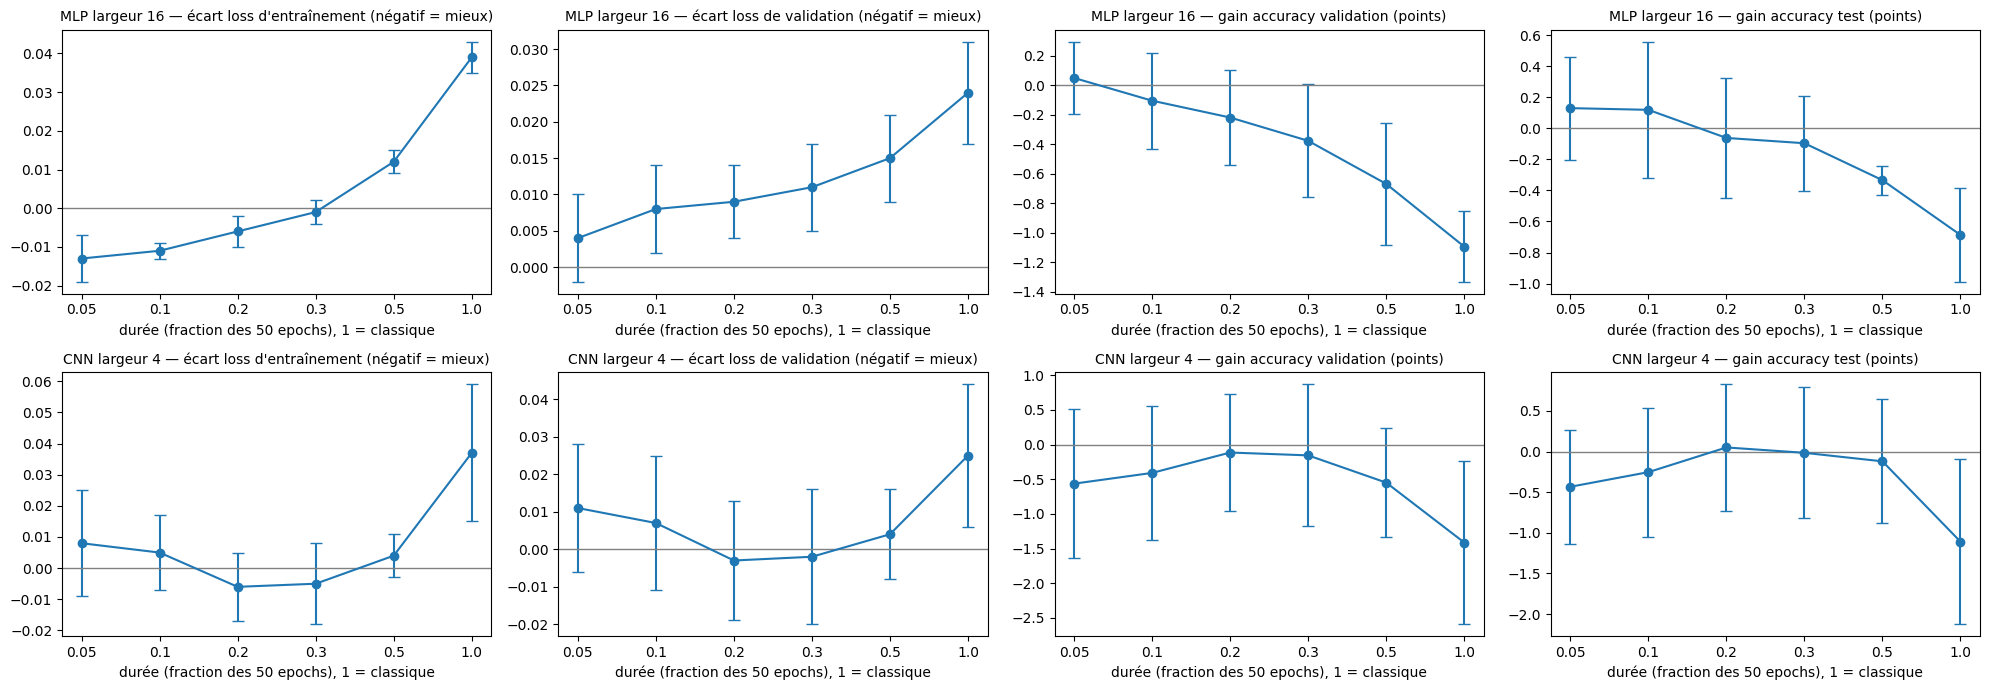

In [76]:
# les mêmes tableaux en figure : gain par rapport à "sans dropout" selon la durée, barres = IC à 95 %
fig, axes = plt.subplots(2, 4, figsize=(20, 7))
titres = {"train_loss": "écart loss d'entraînement (négatif = mieux)",
          "val_loss": "écart loss de validation (négatif = mieux)",
          "val_acc": "gain accuracy validation (points)",
          "test_acc": "gain accuracy test (points)"}
for ligne, (nom, g) in enumerate([("MLP largeur 16", g_mlp), ("CNN largeur 4", g_cnn)]):
    for ax, m in zip(axes[ligne], titres):
        ax.errorbar(range(len(g)), g[m], yerr=g["ic_" + m], marker="o", capsize=4)
        ax.axhline(0, color="gray", lw=1)
        ax.set_xticks(range(len(g)))
        ax.set_xticklabels(g.index)
        ax.set_title(f"{nom} — {titres[m]}", fontsize=10)
        ax.set_xlabel("durée (fraction des 50 epochs), 1 = classique")
plt.tight_layout(); plt.show()

On choisit et on interprète sur la validation ; le test sert de vérification et va dans le même sens, avec des IC du même ordre.

**D'abord la confirmation du régime (ligne 1.0)** : sur 5 seeds le dropout classique fait bien perdre, -1.1 pt de validation sur le MLP et -1.4 pt sur le CNN, avec un IC entièrement négatif. Les deux réglages sont bien en sous-apprentissage.

**MLP** :
- Un early dropout **court** (2 à 10 epochs) fait baisser la loss d'entraînement finale de façon significative (≈ -0.013 pour 2 epochs). C'est exactement ce qu'annonce le papier : le modèle apprend mieux ses données.
- Mais ça ne se voit **pas sur l'accuracy** : aucun gain significatif en validation ni en test. Et la loss de validation **monte** un peu (+0.008 à 10 %, significatif).
- L'effet dépend beaucoup de la durée : plus c'est court mieux c'est, à 30 % il n'y a plus rien, et à partir de 50 % ça se comporte comme du dropout classique (tout se dégrade). Le papier dit que la durée compte peu entre 1 % et 50 % : chez nous ce n'est pas vrai.

**CNN** : rien de détectable. Aucune durée d'early n'a d'effet significatif, ni sur les loss ni sur l'accuracy. Les seeds sont très dispersées (IC d'environ ±1 pt d'accuracy), donc on ne peut pas exclure un petit effet, mais on ne retrouve même pas clairement la baisse de loss d'entraînement du MLP.

### Les courbes : est-ce que les modèles surapprennent ?

Loss d'entraînement (pointillés) et de validation (trait plein) sur le même graphe, moyennées sur les 5 seeds. Un modèle **surapprend** quand sa loss de validation **remonte** alors que celle d'entraînement continue de baisser. Un écart entre les deux courbes ne suffit pas : il y en a toujours un, puisque le modèle est meilleur sur les images qu'il a vues.

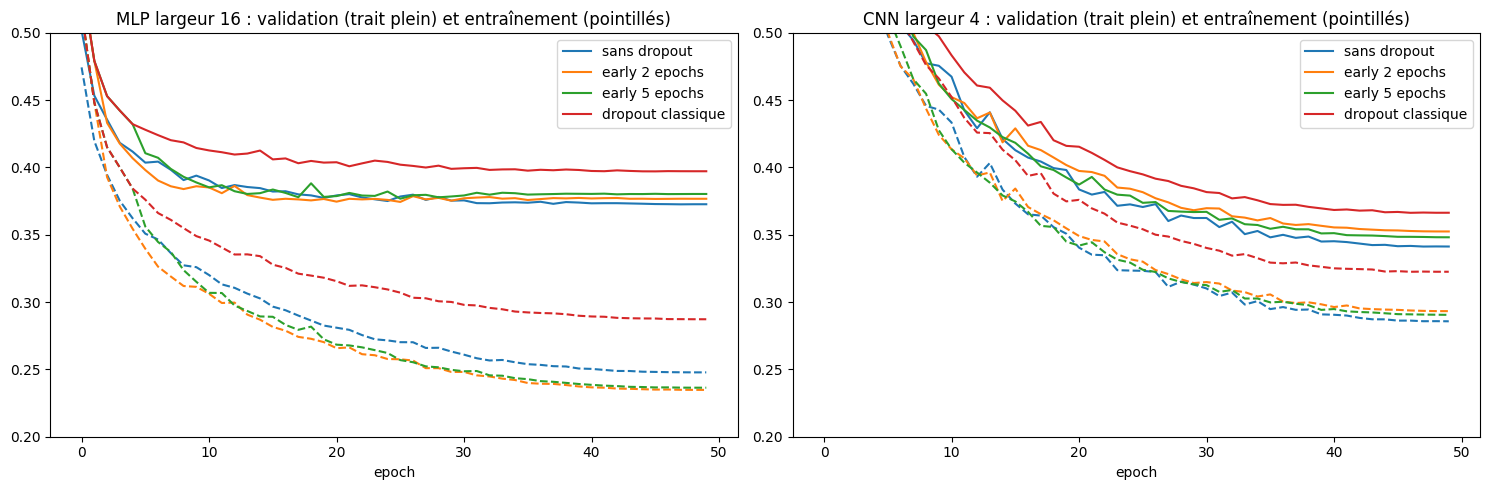

mlp_fmnist sans dropout       minimum de la val loss à l'epoch 47, remontée à la fin : 0.03 %
mlp_fmnist early 2 epochs     minimum de la val loss à l'epoch 25, remontée à la fin : 0.62 %
mlp_fmnist early 5 epochs     minimum de la val loss à l'epoch 25, remontée à la fin : 0.94 %
mlp_fmnist dropout classique  minimum de la val loss à l'epoch 45, remontée à la fin : 0.03 %
cnn_fmnist sans dropout       minimum de la val loss à l'epoch 47, remontée à la fin : 0.05 %
cnn_fmnist early 2 epochs     minimum de la val loss à l'epoch 49, remontée à la fin : 0.07 %
cnn_fmnist early 5 epochs     minimum de la val loss à l'epoch 49, remontée à la fin : 0.06 %
cnn_fmnist dropout classique  minimum de la val loss à l'epoch 46, remontée à la fin : 0.05 %


In [77]:
def nom(frac):
    return {0: "sans dropout", 1: "dropout classique"}.get(frac, f"early {round(frac * 50)} epochs")

fig, axes = plt.subplots(1, 2, figsize=(15, 5))
for ax, (titre, cadre, L) in zip(axes, [("MLP largeur 16", "mlp_fmnist", 16), ("CNN largeur 4", "cnn_fmnist", 4)]):
    for k, frac in enumerate([0, 0.05, 0.1, 1]):
        moy = sum(pd.read_csv(fichier(cadre, L, 50, frac, s))[["train_loss", "val_loss"]] for s in SEEDS) / len(SEEDS)
        ax.plot(moy.val_loss, color=f"C{k}", label=nom(frac))
        ax.plot(moy.train_loss, color=f"C{k}", ls="--")
    ax.set_title(f"{titre} : validation (trait plein) et entraînement (pointillés)")
    ax.set_xlabel("epoch"); ax.set_ylim(0.2, 0.5); ax.legend()
plt.tight_layout(); plt.show()

# de combien la val loss remonte entre son minimum et la fin du run (moyenne des seeds)
for cadre, L in [("mlp_fmnist", 16), ("cnn_fmnist", 4)]:
    for frac in [0, 0.05, 0.1, 1]:
        moy = sum(pd.read_csv(fichier(cadre, L, 50, frac, s)).val_loss for s in SEEDS) / len(SEEDS)
        print(f"{cadre} {nom(frac):18s} minimum de la val loss à l'epoch {moy.idxmin():2d}, "
              f"remontée à la fin : {100 * (moy.tail(5).mean() / moy.min() - 1):.2f} %")

**Sans dropout, aucun des deux ne surapprend.** La val loss ne remonte jamais (minimum vers l'epoch 47, remontée nulle). Sur le CNN elle baisse jusqu'au bout. Sur le MLP elle plafonne dès l'epoch 15 environ, pendant que la loss d'entraînement continue de baisser : le MLP est à la limite, ce qu'il apprend en plus sur le train ne sert plus la validation, sans pour autant la dégrader.

**Les deux notions de "sous-apprentissage" ne sont pas les mêmes.** Celle du papier, qu'on utilise pour la calibration, dit seulement "le dropout classique fait perdre". Ça ne veut pas dire qu'il n'y a aucun écart train/validation, juste qu'enlever de la capacité coûte plus que ça ne régularise.

**Sur le MLP, l'early dropout commence à surapprendre, un tout petit peu.** Avec 2 ou 5 epochs de dropout, la val loss atteint son minimum vers l'epoch 25 puis remonte de 0.6 à 0.9 % jusqu'à la fin, alors que la loss d'entraînement continue de baisser. C'est faible, mais c'est exactement la signature d'un début de surapprentissage, et ça n'arrive pas sans dropout. Sur le CNN rien de tel : toutes les courbes baissent jusqu'au bout.

### Pourquoi la loss d'entraînement baisse mais pas l'accuracy ?

Pour mieux voir, on trace epoch par epoch l'écart avec le run sans dropout de la même seed (MLP).

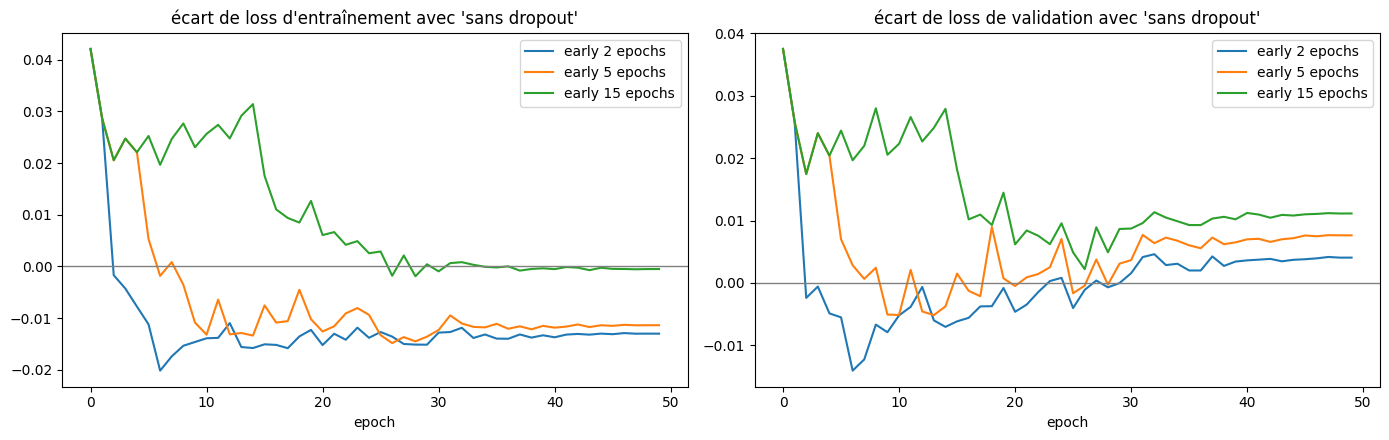

In [78]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))
for frac in [0.05, 0.1, 0.3]:
    # écart avec le run sans dropout de la même seed, puis moyenne sur les seeds
    ecart = sum(pd.read_csv(fichier("mlp_fmnist", 16, 50, frac, s))[["train_loss", "val_loss"]]
                - pd.read_csv(fichier("mlp_fmnist", 16, 50, 0, s))[["train_loss", "val_loss"]] for s in SEEDS) / len(SEEDS)
    axes[0].plot(ecart.train_loss, label=f"early {round(frac * 50)} epochs")
    axes[1].plot(ecart.val_loss, label=f"early {round(frac * 50)} epochs")
axes[0].set_title("écart de loss d'entraînement avec 'sans dropout'")
axes[1].set_title("écart de loss de validation avec 'sans dropout'")
for ax in axes:
    ax.axhline(0, color="gray", lw=1)
    ax.set_xlabel("epoch"); ax.legend()
plt.tight_layout(); plt.show()

Pendant la phase de dropout le modèle est en retard (écart positif), puis dès qu'on coupe il passe **devant** et garde une loss d'entraînement plus basse jusqu'à la fin : c'est le comportement décrit dans l'annexe G du papier.

Mais la loss de validation, elle, n'est en dessous que jusqu'au milieu de l'entraînement, puis elle repasse au-dessus. Le modèle avec early dropout apprend plus vite, donc il arrive aussi plus tôt au moment où continuer à apprendre le train ne sert plus à la validation : c'est le léger surapprentissage vu juste au-dessus (minimum vers l'epoch 25, contre 47 sans dropout). Sur 50 epochs, l'ajustement gagné part dans l'écart train/validation.

Si c'est ça, le résultat devrait dépendre du budget : sur un entraînement plus court, l'early dropout devrait aider aussi la validation.

---
## 3. Est-ce que ça dépend du nombre d'epochs ?

On refait la grille sur un budget de 20 epochs : le même MLP (largeur 16, valide aussi à 20 epochs), et le CNN largeur 8 (l'autre case valide de la calibration). À 20 epochs les durées font 1, 2, 4, 6 et 10 epochs.

(Ces runs datent d'avant : pour le MLP la loss d'entraînement y est mesurée sur tout le train et pas sur 10 000 images, mais c'est pareil pour tous les runs du tableau donc les écarts se comparent. Le CNN n'a pas la durée 0.05.)

In [79]:
for frac in EARLY_GRID:
    for seed in SEEDS:
        lancer("mlp_fmnist", 16, 20, frac, seed)

gains("mlp_fmnist", 16, 20, EARLY_GRID[1:], SEEDS)

,train_loss,ic_train_loss,val_loss,ic_val_loss,val_acc,ic_val_acc,test_acc,ic_test_acc
0.05,-0.013,0.006,-0.008,0.004,0.082,0.153,0.046,0.241
0.10,-0.015,0.007,-0.009,0.007,0.106,0.276,0.074,0.265
0.20,-0.011,0.007,-0.004,0.009,-0.020,0.292,0.054,0.316
0.30,-0.006,0.007,-0.001,0.009,-0.233,0.291,-0.016,0.361
0.50,0.005,0.007,0.007,0.009,-0.493,0.179,-0.285,0.262
1.00,0.026,0.006,0.022,0.009,-1.110,0.188,-0.890,0.226


In [80]:
for frac in [0, 0.1, 0.2, 0.3, 0.5, 1]:
    for seed in SEEDS:
        lancer("cnn_fmnist", 8, 20, frac, seed)

gains("cnn_fmnist", 8, 20, [0.1, 0.2, 0.3, 0.5, 1], SEEDS)

,train_loss,ic_train_loss,val_loss,ic_val_loss,val_acc,ic_val_acc,test_acc,ic_test_acc
0.1,-0.003,0.011,-0.002,0.009,-0.026,0.189,0.096,0.202
0.2,-0.005,0.010,-0.002,0.010,-0.018,0.154,0.206,0.327
0.3,-0.005,0.011,-0.003,0.011,0.112,0.148,0.102,0.403
0.5,0.001,0.010,-0.001,0.008,-0.147,0.111,0.034,0.425
1.0,0.018,0.011,0.008,0.013,-0.488,0.373,-0.341,0.439


**MLP à 20 epochs** : même baisse de loss d'entraînement qu'à 50 epochs (≈ -0.013 à -0.015 pour 1 ou 2 epochs de dropout), et cette fois la loss de validation **baisse aussi** de façon significative (≈ -0.008). L'accuracy monte de +0.1 pt, pas significatif. Ça confirme l'explication : l'early dropout fait prendre de l'avance, ce qui aide la validation tant que le modèle n'a pas fini de converger (20 epochs) et plus du tout quand il a fini (50 epochs).

Pour relativiser : passer de 20 à 50 epochs sans dropout fait gagner ~0.5 pt de validation, bien plus que tout ce que fait l'early dropout.

**CNN largeur 8 à 20 epochs** : toujours aucun gain pour l'early, avec cette fois des IC serrés (±0.1 à 0.2 pt d'accuracy de validation) : un effet de quelques dixièmes de point se serait vu. La seule chose significative est une petite perte à 50 % (-0.15 pt). Et avec 5 seeds le dropout classique ne fait perdre que ~0.5 pt : ce réglage était limite, c'est pour ça qu'on confirme toujours le régime sur 5 seeds.

---
## 4. Contrôle : et si le modèle surapprend ?

Pour vérifier que le protocole mesure bien ce qu'on croit, on prend les deux réglages où la calibration disait "surapprentissage" (MLP largeur 64 et CNN largeur 16, à 50 epochs). On doit y trouver l'inverse : le dropout classique aide, et l'early dropout n'a pas de raison d'aider.

3 seeds, donc des IC plus larges (t = 4.30).

In [81]:
for frac in [0, 0.1, 1]:
    for seed in [0, 1, 2]:
        lancer("mlp_fmnist", 64, 50, frac, seed)
        lancer("cnn_fmnist", 16, 50, frac, seed)

pd.concat({"MLP largeur 64": gains("mlp_fmnist", 64, 50, [0.1, 1], [0, 1, 2]),
           "CNN largeur 16": gains("cnn_fmnist", 16, 50, [0.1, 1], [0, 1, 2])})

train_loss  ic_train_loss  val_loss  ic_val_loss  val_acc  \
MLP largeur 64 0.1      -0.007          0.006     0.015        0.046    0.047   
               1.0       0.041          0.004    -0.076        0.013    0.527   
CNN largeur 16 0.1      -0.005          0.019     0.063        0.202   -0.138   
               1.0       0.055          0.009    -0.190        0.063    0.834   

                    ic_val_acc  test_acc  ic_test_acc  
MLP largeur 64 0.1       0.438    -0.097        0.339  
               1.0       0.400     0.274        0.600  
CNN largeur 16 0.1       0.487    -0.191        0.393  
               1.0       0.717     0.888        0.639

C'est bien l'inverse du cadre principal : le dropout classique **fait gagner** en validation (+0.5 pt sur le MLP, +0.8 pt sur le CNN, significatif) et fait baisser la val loss, alors que l'early dropout ne change pas l'accuracy. Le critère de régime fonctionne donc dans les deux sens.

Un détail intéressant : sur le MLP largeur 64, l'early dropout fait quand même baisser un peu la loss d'entraînement (-0.007). L'effet "le modèle apprend mieux le train" n'est donc pas réservé au sous-apprentissage, c'est un effet sur l'optimisation.

---
## 5. Sensibilité au taux de dropout : p = 0.3

L'étude sur CIFAR-10 a tout fait avec p = 0.3. Pour savoir si on peut comparer, on refait nos deux cadres principaux à p = 0.3 sur les durées 0.1, 0.3 et 1. Le run sans dropout ne dépend pas de p, donc on garde la même référence. Les CSV vont dans `resultats/p03/`.

In [82]:
os.makedirs("resultats/p03", exist_ok=True)
for frac in [0.1, 0.3, 1]:
    for seed in SEEDS:
        lancer("mlp_fmnist", 16, 50, frac, seed, p=0.3, dossier="resultats/p03")
        lancer("cnn_fmnist", 4, 50, frac, seed, p=0.3, dossier="resultats/p03")

pd.concat({
    "MLP p=0.1": g_mlp.loc[[0.1, 0.3, 1]],
    "MLP p=0.3": gains("mlp_fmnist", 16, 50, [0.1, 0.3, 1], SEEDS, dossier="resultats/p03"),
    "CNN p=0.1": g_cnn.loc[[0.1, 0.3, 1]],
    "CNN p=0.3": gains("cnn_fmnist", 4, 50, [0.1, 0.3, 1], SEEDS, dossier="resultats/p03"),
})

train_loss  ic_train_loss  val_loss  ic_val_loss  val_acc  \
MLP p=0.1 0.1      -0.011          0.002     0.008        0.006   -0.106   
          0.3      -0.001          0.003     0.011        0.006   -0.378   
          1.0       0.039          0.004     0.024        0.007   -1.095   
MLP p=0.3 0.1      -0.008          0.009     0.007        0.008   -0.065   
          0.3       0.015          0.012     0.016        0.007   -0.484   
          1.0       0.128          0.013     0.094        0.009   -2.923   
CNN p=0.1 0.1       0.005          0.012     0.007        0.018   -0.408   
          0.3      -0.005          0.013    -0.002        0.018   -0.155   
          1.0       0.037          0.022     0.025        0.019   -1.412   
CNN p=0.3 0.1      -0.001          0.025    -0.001        0.024   -0.208   
          0.3       0.002          0.033     0.003        0.023   -0.302   
          1.0       0.111          0.056     0.090        0.043   -3.977   

               ic_val_acc  test_acc  ic_test_acc  
MLP p=0.1 0.1       0.326     0.119        0.438  
          0.3       0.383    -0.096        0.307  
          1.0       0.238    -0.687        0.301  
MLP p=0.3 0.1       0.329     0.066        0.576  
          0.3       0.472    -0.275        0.233  
          1.0       0.583    -2.465        0.397  
CNN p=0.1 0.1       0.966    -0.253        0.795  
          0.3       1.025    -0.015        0.808  
          1.0       1.179    -1.109        1.016  
CNN p=0.3 0.1       0.987    -0.090        1.077  
          0.3       0.864    -0.292        1.032  
          1.0       1.276    -3.642        1.510

- **Dropout classique** : à p = 0.3 il fait beaucoup plus mal (-2.9 pt sur le MLP, -4.0 pt sur le CNN, contre -1.1 et -1.4 à p = 0.1). Pour nos tout petits modèles, 0.3 tout le long est trop fort.
- **Early court (10 %)** : pareil qu'à p = 0.1, accuracy inchangée, loss d'entraînement un peu plus basse sur le MLP (pas significatif ici).
- **Early 30 %** : à p = 0.1 la perte n'était pas significative (-0.4 pt), à p = 0.3 elle le devient (-0.5 pt sur le MLP) et la loss d'entraînement finit plus haute au lieu de plus basse. Plus le taux est fort, plus il faut couper tôt.

Donc les conclusions restent les mêmes à p = 0.3, mais la fenêtre utile rétrécit : on ne compare les **durées** avec CIFAR-10 qu'à p égal.

**Est-ce que c'est juste la quantité totale de dropout qui compte ?** Sur le MLP, 15 epochs à p = 0.1 et 5 epochs à p = 0.3 font la même "dose" (p × durée). Pourtant le deuxième est meilleur : loss d'entraînement -0.008 contre -0.001, accuracy -0.07 contre -0.38. À dose égale, court et fort vaut mieux que long et faible : c'est bien le fait d'être **tôt** qui compte.

### La position du dropout

Autre différence avec CIFAR-10 : eux ont un seul dropout, juste avant la couche de sortie. On teste cette position sur notre MLP (on enlève le premier dropout), à p = 0.3.

In [83]:
def mlp_tete(L):
    model, opt = mlp(784, 10, couche_cache=L)
    model[2] = nn.Identity()          # on enlève le 1er dropout : il reste seulement celui avant la sortie
    return model, opt

CADRES["mlp_tete_fmnist"] = (mlp_tete, vecteurs)

for frac in [0.1, 0.3, 1]:
    for seed in SEEDS:
        lancer("mlp_tete_fmnist", 16, 50, frac, seed, p=0.3, dossier="resultats/p03")

# sans dropout ce modèle est le même que le MLP normal, donc même référence
gains("mlp_tete_fmnist", 16, 50, [0.1, 0.3, 1], SEEDS, dossier="resultats/p03", reference="mlp_fmnist")

,train_loss,ic_train_loss,val_loss,ic_val_loss,val_acc,ic_val_acc,test_acc,ic_test_acc
0.1,-0.003,0.007,0.005,0.009,-0.065,0.313,0.243,0.382
0.3,0.005,0.007,0.011,0.009,-0.247,0.353,0.143,0.425
1.0,0.035,0.008,0.030,0.008,-0.879,0.385,-0.482,0.382


Un seul dropout à 0.3 avant la sortie fait perdre ~0.9 pt en dropout classique, à peu près comme nos deux dropouts à 0.1 (-1.1 pt). Leur réglage est donc une intervention de force comparable à notre réglage principal, et l'early n'y a pas plus d'effet sur l'accuracy.

---
## Conclusion pour Fashion-MNIST

**Q1 — est-ce que l'early dropout marche à notre échelle ?**
- *En partie sur le MLP* : un early dropout court fait baisser la loss d'entraînement finale de façon nette et répétable (≈ -0.013, à 20 comme à 50 epochs). Le mécanisme du papier ("le modèle apprend mieux") se retrouve donc sur un MLP de 13 000 paramètres.
- *Mais pas sur la généralisation* : aucun gain d'accuracy significatif, dans aucun réglage. La loss de validation s'améliore un peu sur un budget court (20 epochs) et se dégrade un peu sur un budget long (50 epochs) : l'early dropout fait surtout prendre de l'avance au modèle.
- *Rien de détectable sur le CNN*, ni à largeur 4 ni à largeur 8.

**Q2 — quelle durée ?**
- Le plus court est le mieux : 1 à 2 epochs (5 à 10 % de l'entraînement). L'effet diminue régulièrement quand on allonge, disparaît vers 30 %, et à partir de 50 % l'early dropout se comporte comme du dropout classique.
- La plage "de 1 % à 50 %" du papier ne tient donc pas à notre échelle, et elle rétrécit encore quand le taux augmente (à p = 0.3, 30 % fait déjà perdre).
- À quantité de dropout égale, court et fort vaut mieux que long et faible : "early" veut vraiment dire "au tout début".

**Ce qui rend ces résultats crédibles** : le régime est calibré puis confirmé sur 5 seeds, et le contrôle en surapprentissage donne bien l'inverse (le dropout classique aide, l'early non).

**Limites** :
- 5 seeds : on ne voit que les effets plus grands que ~0.3 pt d'accuracy sur le MLP et ~1 pt sur le CNN largeur 4. "Pas détecté" ne veut pas dire "nul".
- Un seul jeu de données, des modèles 1000 fois plus petits que ceux du papier, pas d'augmentation (le papier en utilise beaucoup, ce qui crée du sous-apprentissage d'une autre façon).
- On n'a pas testé si le "début" se compte en epochs ou en itérations (Q3, en changeant la taille de batch).